# HRP-UWB: Native Demodulation and Capture Analysis

This notebook sends the selected recording to the **compiled C++ UWB core through the native C ABI**, using `demod.demodulate(demod.UWB_HRP, iq, config)`. It defaults to the repaired **802.15.4a channel 9, code 3, 6.81 Mbps, 100-byte PSDU** capture under `captures/generated/uwb`. Change `capture` to select another generated legacy, BPRF, HPRF, or EHPRF recording with a matching `.para2` file. Legacy 4a uses the native mode-0 repetition detector; this is not a full legacy PHY decoder.

1. Read I/Q samples, sample rate, and generator settings; map the PHY name to a native mode explicitly.
2. Run native burst detection, preamble synchronization, and CFO estimation.
3. Plot I/Q, power, spectrum, and preamble diagnostics using native timing and frequency results.
4. Verify the same selected capture with a known +25 kHz shift and empty-input rejection.
5. Compare native CFO with hash-matched saved 89600 measurements; optionally replay the selected capture live.
6. Run native checks and strict VSA comparisons across all bundled UWB captures.

**Scope:** the native HRP API returns burst detection, preamble timing, repetition correlation, and frequency offset. It does not expose code-index verification, SFD/PHR parsing, BPM-BPSK payload decisions, FEC decoding, CRC, EVM, or a decoded PSDU. Repetition plots are independent diagnostics, not internal native traces or a code-matched detector. `PayloadHex` is generator ground truth, not recovered data. VSA NRMSE remains a VSA-only measurement.

**Legacy 4a export provenance:** the generated 6.81 Mbps / 15.6 MHz recording uses `LegacyHoppingConvention=VsaTrailingPnWindow` to match VSA's hopping window for two-chip bursts with eight hop positions. Only burst positions change; PN advancement, spreading chips, coding, payload bits, and the header are preserved. The original MATLAB recording and its failed measurement are archived in [uwb_legacy_original_20261016.json](../../../reports/uwb_legacy_original_20261016.json). Use `gen_uwb(outRoot, false)` to export unmodified MATLAB hopping. Passing this interoperability check is not independent IEEE conformance certification.

In [1]:
import faulthandler
faulthandler.enable()
%matplotlib inline
import csv
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

if os.name == "nt":
    packages = Path(os.environ["LOCALAPPDATA"]) / "Microsoft" / "WinGet" / "Packages"
    for runtime_dir in packages.glob("BrechtSanders.WinLibs.POSIX.UCRT_*/mingw64/bin"):
        os.environ["PATH"] = str(runtime_dir) + os.pathsep + os.environ.get("PATH", "")

root = next((directory for directory in (Path.cwd(), *Path.cwd().parents)
             if (directory / "nrdemod" / "python" / "nrdemod").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run this notebook from within the nrdemod-vsa workspace")
sys.path.insert(0, str(root / "nrdemod" / "python"))
from nrdemod import demod
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
print(f"Native demodulator {demod.version()}")
print(f"Workspace: {root}")

Native demodulator 1.0.0
Workspace: c:\code\nrdemod-vsa


In [2]:
# 1. Load the repaired legacy capture and run the compiled native UWB core.
capture = root / "captures/generated/uwb/UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt"
metadata_path = capture.with_suffix(".para2")
settings = {}
with metadata_path.open(newline="", encoding="utf-8-sig") as stream:
    for row in csv.reader(stream, skipinitialspace=True):
        if len(row) >= 4:
            settings[row[1].strip()] = row[3].strip()

header = {}
with capture.open(encoding="utf-8-sig") as stream:
    for line in stream:
        if line.strip() == "Y":
            break
        parts = line.split()
        if len(parts) >= 2:
            header[parts[0]] = parts[1]
    else:
        raise ValueError("The capture has no Y data marker")
    samples = np.loadtxt(stream)
assert samples.ndim == 2 and samples.shape[1] == 2, "Expected I and Q columns"
iq = (samples[:, 0] + 1j * samples[:, 1]).astype(np.complex64)
fs = 1.0 / float(header["XDelta"])
assert np.isclose(fs, float(settings["SampleRate"]), rtol=1e-8)
assert iq.size == int(settings["NumSamples"])
assert np.isfinite(iq).all() and np.max(np.abs(iq)) > 0
mode = settings["Mode"].upper()
native_modes = {"BPRF": demod.UWB_BPRF, "HPRF": demod.UWB_HPRF,
                "EHPRF": demod.UWB_EHPRF, "802.15.4A": demod.UWB_BPRF}
if mode not in native_modes:
    raise ValueError(f"Unsupported mode for this notebook: {mode}")
config = demod.Config(sampleRate=fs, phyMode=native_modes[mode],
                      syncLength=int(settings["SyncLength"]),
                      chipRateHz=float(settings.get("ChipRate", 499.2e6)))
print(capture.name)
print(f"{iq.size:,} samples | {fs / 1e9:.5f} GSa/s | {iq.size / fs * 1e6:.3f} us")
print(f"{mode} | native mode {config.phyMode} | code {settings['CodeIndex']} | sync {config.syncLength} | SP{settings['StsPacketConfig']}")
print(f"Center frequency: {float(header['InputCenter']) / 1e9:.5f} GHz")
print(f"Legacy hopping convention: {settings.get('LegacyHoppingConvention', 'not applicable')}")
result = demod.demodulate(demod.UWB_HRP, iq, config)
assert result.ok, result.error
assert result.burstFound and result.syncFound, result.as_dict()
metrics = result.as_dict()
for name, value in metrics.items():
    print(f"{name:30s} {value}")

UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt
435,508 samples | 1.99680 GSa/s | 218.103 us
802.15.4A | native mode 0 | code 3 | sync 64 | SP0
Center frequency: 7.98720 GHz
Legacy hopping convention: VsaTrailingPnWindow
burstFound                     True
syncFound                      True
burstStart                     4060
burstLength                    429428
syncPositionSamples            4060
syncRho                        0.9913648089237391
frequencyErrorHz               -0.0
preambleSymbolPeriodSamples    1984.0
ok                             True
error                          
family                         UWB-HRP


In [3]:
# 2. Inspect I/Q and power; overlay the native burst interval.
time_us = np.arange(iq.size) / fs * 1e6
power = np.abs(iq.astype(np.complex128)) ** 2
power_db = 10 * np.log10(np.maximum(power / power.max(), 1e-12))
burst_start = int(result.burstStart)
burst_end = min(iq.size, burst_start + int(result.burstLength))
sync_start = int(result.syncPositionSamples)
period = int(round(result.preambleSymbolPeriodSamples))
assert period > 0 and 0 <= sync_start < iq.size
stride = max(1, iq.size // 25000)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(time_us[::stride], iq.real[::stride], label="I", linewidth=0.6)
axes[0].plot(time_us[::stride], iq.imag[::stride], label="Q", linewidth=0.6, alpha=0.7)
axes[0].set(ylabel="Amplitude (V)", title=f"Recorded HRP waveform (display stride {stride}; processing uses all samples)")
axes[0].legend()
axes[1].plot(time_us[::stride], power_db[::stride], linewidth=0.6)
axes[1].axvspan(burst_start / fs * 1e6, burst_end / fs * 1e6,
                color="tab:green", alpha=0.15, label="Native burst")
axes[1].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[1].set(xlabel="Time (us)", ylabel="Instantaneous power (dB re peak)", ylim=(-80, 3))
axes[1].legend()
plt.show()
print(f"Burst: samples [{burst_start}, {burst_end}); duration {(burst_end - burst_start) / fs * 1e6:.3f} us")

: 

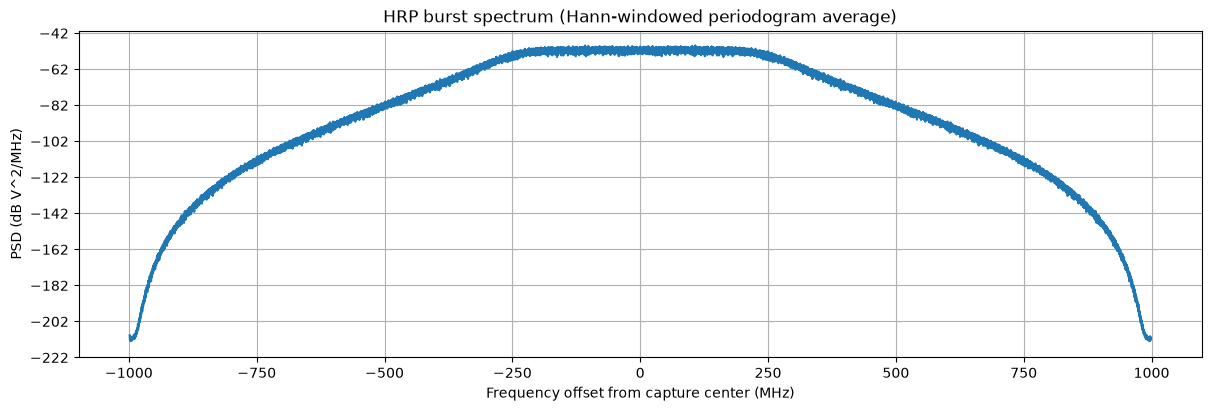

In [ ]:
# 3. Estimate the two-sided complex-baseband power spectral density.
fig, axis = plt.subplots(figsize=(12, 4), constrained_layout=True)
axis.psd(iq[burst_start:burst_end], NFFT=8192, Fs=fs / 1e6,
         sides="twosided", scale_by_freq=True)
axis.set(title="HRP burst spectrum (Hann-windowed periodogram average)",
         xlabel="Frequency offset from capture center (MHz)", ylabel="PSD (dB V^2/MHz)")
plt.show()

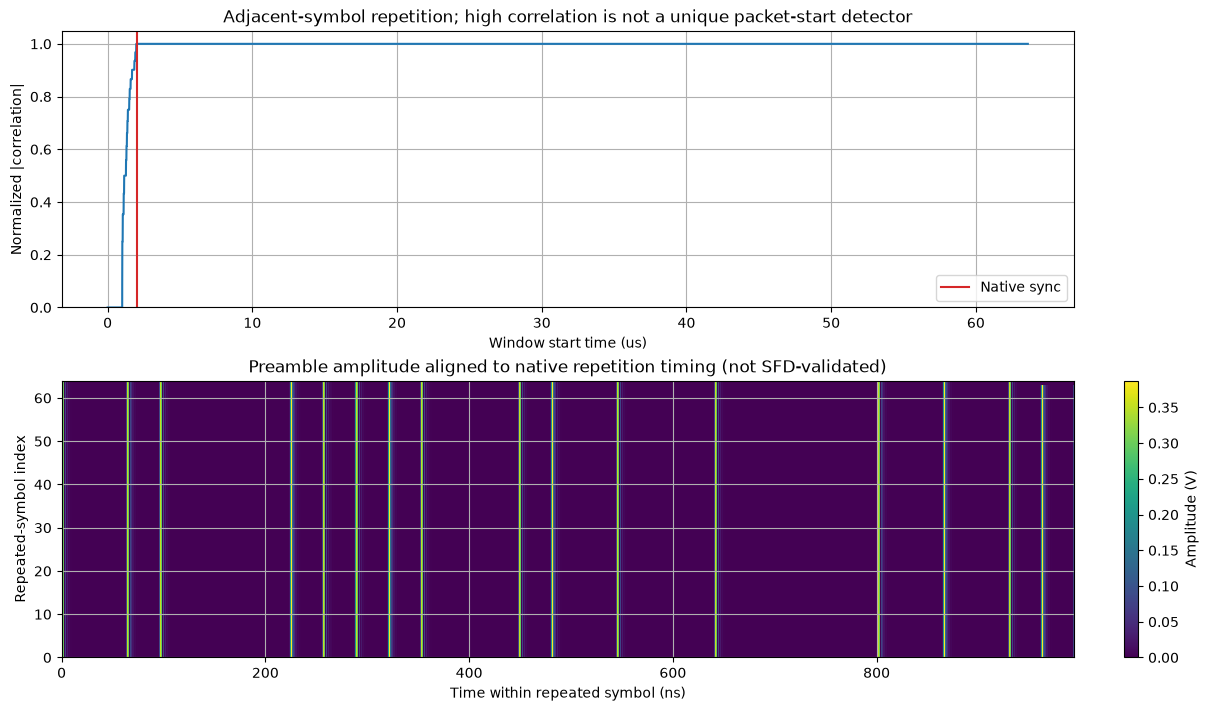

Native period: 1984 samples = 993.590 ns
Native sync rho: 0.991365; independent repetition maximum: 1.000000


In [ ]:
# 4. Measure normalized repetition correlation between adjacent preamble symbols.
# This is a notebook diagnostic, not an internal native-core trace.
window_count = min(64 * period, iq.size - 2 * period)
assert window_count > 0
first = iq[:window_count + period].astype(np.complex128)
second = iq[period:window_count + 2 * period].astype(np.complex128)

def moving_sum(values, length):
    cumulative = np.concatenate(([0], np.cumsum(values)))
    return cumulative[length:] - cumulative[:-length]

cross = moving_sum(np.conj(first) * second, period)
energy_first = moving_sum(np.abs(first) ** 2, period).real
energy_second = moving_sum(np.abs(second) ** 2, period).real
denominator = np.sqrt(np.maximum(energy_first, 0) * np.maximum(energy_second, 0))
rho = np.divide(np.abs(cross), denominator, out=np.zeros_like(denominator),
                where=denominator > np.max(denominator) * 1e-8)
rho = np.clip(rho, 0, 1)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(np.arange(rho.size) / fs * 1e6, rho)
axes[0].axvline(sync_start / fs * 1e6, color="tab:red", label="Native sync")
axes[0].set(xlabel="Window start time (us)", ylabel="Normalized |correlation|", ylim=(0, 1.05),
            title="Adjacent-symbol repetition; high correlation is not a unique packet-start detector")
axes[0].legend()
preamble_count = min(config.syncLength, (iq.size - sync_start) // period)
assert preamble_count >= 2
preamble = iq[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
image = axes[1].imshow(np.abs(preamble), aspect="auto", origin="lower", interpolation="nearest",
                        extent=(0, period / fs * 1e9, 0, preamble_count), cmap="viridis")
axes[1].set(xlabel="Time within repeated symbol (ns)", ylabel="Repeated-symbol index",
            title="Preamble amplitude aligned to native repetition timing (not SFD-validated)")
fig.colorbar(image, ax=axes[1], label="Amplitude (V)")
plt.show()
assert np.isfinite(rho).all()
print(f"Native period: {period} samples = {period / fs * 1e9:.3f} ns")
print(f"Native sync rho: {result.syncRho:.6f}; independent repetition maximum: {rho.max():.6f}")

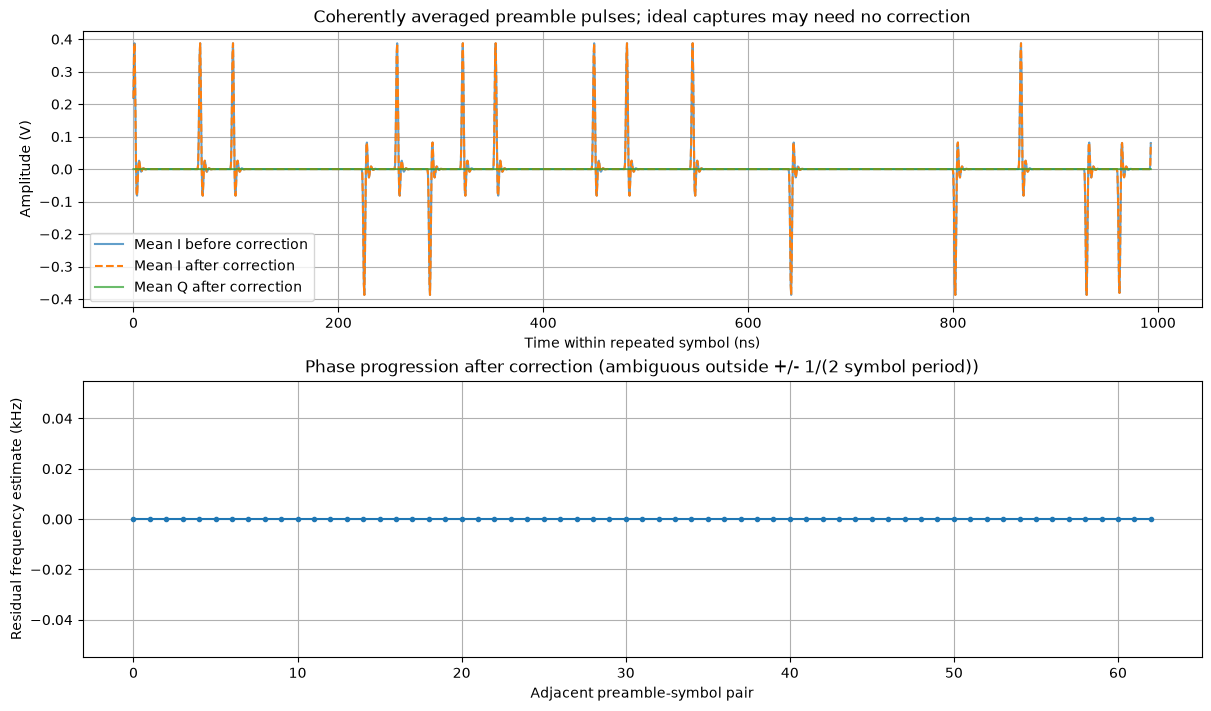

Applied native frequency correction: -0.000 Hz
Median repetition-based residual: 0.000 Hz

Receiver summary
Burst detected: True; preamble synchronized: True
Sync sample: 4060; sync metric: 0.991365
Payload decoding, CRC, and EVM: NOT AVAILABLE in the native HRP API
Generator reference only: PSDU length 100 bytes


In [ ]:
# 5. Correct the native frequency estimate and coherently average preamble pulses.
frequency_error_hz = float(result.frequencyErrorHz)
corrected = iq * np.exp(-2j * np.pi * frequency_error_hz * np.arange(iq.size) / fs)
aligned = corrected[sync_start:sync_start + preamble_count * period].reshape(preamble_count, period)
average_before = preamble.mean(axis=0)
average_after = aligned.mean(axis=0)
phase_step = np.angle(np.sum(np.conj(aligned[:-1]) * aligned[1:], axis=1))
residual_hz = phase_step * fs / (2 * np.pi * period)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
within_ns = np.arange(period) / fs * 1e9
axes[0].plot(within_ns, average_before.real, label="Mean I before correction", alpha=0.7)
axes[0].plot(within_ns, average_after.real, "--", label="Mean I after correction")
axes[0].plot(within_ns, average_after.imag, label="Mean Q after correction", alpha=0.7)
axes[0].set(xlabel="Time within repeated symbol (ns)", ylabel="Amplitude (V)",
            title="Coherently averaged preamble pulses; ideal captures may need no correction")
axes[0].legend()
axes[1].plot(np.arange(residual_hz.size), residual_hz / 1e3, marker=".")
axes[1].set(xlabel="Adjacent preamble-symbol pair", ylabel="Residual frequency estimate (kHz)",
            title="Phase progression after correction (ambiguous outside +/- 1/(2 symbol period))")
plt.show()
assert np.isfinite(corrected).all() and np.isfinite(residual_hz).all()
print(f"Applied native frequency correction: {frequency_error_hz:.3f} Hz")
print(f"Median repetition-based residual: {np.median(residual_hz):.3f} Hz")

# 6. Report only receiver results actually available from this core.
print("\nReceiver summary")
print(f"Burst detected: {result.burstFound}; preamble synchronized: {result.syncFound}")
print(f"Sync sample: {sync_start}; sync metric: {result.syncRho:.6f}")
print("Payload decoding, CRC, and EVM: NOT AVAILABLE in the native HRP API")
print(f"Generator reference only: PSDU length {settings['PSDULength']} bytes")

## Native C-ABI Verification and 89600 Correlation

The following cells use the **same selected capture, native configuration, and native result** as the plots above. They verify synchronization, a known +25 kHz frequency shift with a 100 Hz recovery tolerance, and empty-input rejection. They do not establish payload-decoding accuracy or run the CMake unit-test suite.

Saved VSA measurements are read from `reports/uwb_vsa_all_20261016.csv` only when capture path, waveform name, and SHA256 match. Required fields depend on the packet configuration: SHR and CFO always; PHR/PSDU when payload is present; STS when enabled. Legacy 4a has no STS. Missing, nonfinite, and no-result sentinel values are rejected.

Limits are native/VSA CFO agreement within **100 Hz**, SHR/STS NRMSE at most **0.5%**, and PHR/PSDU NRMSE at most **2%**. NRMSE is a VSA-only quality measurement; there is no native payload EVM to compare. Timing and repetition-correlation values are not treated as equivalent across receivers.

The repaired legacy capture has a recorded passing VSA measurement. The all-capture report currently has **15 native passes, 12 VSA correlation passes, zero correlation failures, and three EHPRF cases unsupported by VSA**. The legacy export follows the explicitly labeled VSA hopping convention described above; this is interoperability validation, not independent IEEE conformance certification.

Leave `run_vsa_measurement=False` to compare with saved measurements. Set it to `True` to replay only the selected waveform through an already-running VSA without restarting the application. The selected-capture JSON report records native configuration/results, input-file hash, VSA timestamp/source, and the actual comparison outcome. The final cells retain the full capture-inventory reports.

In [ ]:
# 7. Verify the selected capture's native C-ABI result, known CFO shift, and empty-input rejection.
reference_capture = capture
reference_iq, reference_fs = iq, fs
reference_config = config
reference_result = result
assert reference_result.ok and reference_result.burstFound and reference_result.syncFound, reference_result.as_dict()
print(f"Shared native/VSA capture: {reference_capture.name}")
print(f"{reference_iq.size:,} samples at {reference_fs / 1e9:.5f} GSa/s")
print(reference_result.as_dict())

injected_cfo_hz = 25000.0
shifted_reference = reference_iq * np.exp(2j * np.pi * injected_cfo_hz * np.arange(reference_iq.size) / reference_fs)
shifted_reference_result = demod.demodulate(demod.UWB_HRP, shifted_reference, reference_config)
assert shifted_reference_result.ok and shifted_reference_result.syncFound, shifted_reference_result.as_dict()
measured_cfo_shift_hz = shifted_reference_result.frequencyErrorHz - reference_result.frequencyErrorHz
np.testing.assert_allclose(measured_cfo_shift_hz, injected_cfo_hz, atol=100.0, rtol=0)
empty_reference_result = demod.demodulate(demod.UWB_HRP, np.empty(0, dtype=np.complex64), reference_config)
assert not empty_reference_result.ok
print(f"PASS: selected-capture synchronization, +25 kHz CFO recovery ({measured_cfo_shift_hz:.3f} Hz), and empty-input rejection")
print("Native scope remains burst/preamble/CFO only; no native PHR/PSDU EVM or payload result is inferred.")

Shared native/VSA capture: UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt
435,508 samples at 1.99680 GSa/s
{'burstFound': True, 'syncFound': True, 'burstStart': 4060, 'burstLength': 429428, 'syncPositionSamples': 4060, 'syncRho': 0.9913648089237391, 'frequencyErrorHz': -0.0, 'preambleSymbolPeriodSamples': 1984.0, 'ok': True, 'error': '', 'family': 'UWB-HRP'}


PASS: selected-capture synchronization, +25 kHz CFO recovery (25000.000 Hz), and empty-input rejection
Native scope remains burst/preamble/CFO only; no native PHR/PSDU EVM or payload result is inferred.


In [ ]:
# 8. VSA NRMSE table values are percentages; required fields depend on the packet configuration.
def check_uwb_correlation(native_metrics, vsa_metrics, cfo_tolerance_hz=100.0, packet_config=0):
    if packet_config not in (0, 1, 2, 3):
        raise ValueError(f"Unsupported STS packet configuration: {packet_config}")
    required = ["FreqErr", "ShrNrmse"]
    if packet_config != 3:
        required += ["PhrNrmse", "PsduNrmse"]
    if packet_config:
        required += ["StsNrmse"]
    missing = [name for name in required if name not in vsa_metrics]
    if missing:
        raise ValueError(f"VSA lacks required SP{packet_config} metrics: {missing}")
    values = {name: float(vsa_metrics[name]) for name in required}
    if not all(np.isfinite(value) and abs(value) < np.finfo(np.float32).max for value in values.values()):
        raise ValueError("VSA returned nonfinite metrics or a no-result sentinel")
    native_cfo = float(native_metrics["frequencyErrorHz"])
    native_rho = float(native_metrics["syncRho"])
    native_valid = bool(native_metrics["ok"] and native_metrics["burstFound"] and native_metrics["syncFound"]
                        and np.isfinite(native_cfo) and np.isfinite(native_rho) and native_rho >= 0.5)
    limits_percent = {"ShrNrmse": 0.5, "StsNrmse": 0.5, "PhrNrmse": 2.0, "PsduNrmse": 2.0}
    vsa_lock_quality = bool(all(0 <= values[name] <= limits_percent[name] for name in required if name != "FreqErr"))
    cfo_difference_hz = native_cfo - values["FreqErr"]
    checked = {"native_sync_valid": native_valid, "vsa_lock_quality_pass": vsa_lock_quality,
               "native_frequency_error_hz": native_cfo, "vsa_frequency_error_hz": values["FreqErr"],
               "cfo_difference_hz": cfo_difference_hz,
               "cfo_agreement_pass": bool(abs(cfo_difference_hz) <= cfo_tolerance_hz),
               "packet_config": packet_config, "limits_percent": limits_percent,
               "pass": bool(native_valid and vsa_lock_quality and abs(cfo_difference_hz) <= cfo_tolerance_hz)}
    for label, name in (("shr", "ShrNrmse"), ("sts", "StsNrmse"), ("phr", "PhrNrmse"), ("psdu", "PsduNrmse")):
        checked[f"vsa_{label}_nrmse_percent"] = values.get(name)
        checked[f"vsa_{label}_nrmse_ratio"] = values[name] / 100 if name in values else None
    return checked


validation_native = {"ok": True, "burstFound": True, "syncFound": True,
                     "syncRho": 0.99, "frequencyErrorHz": 0.0}
validation_vsa = {"FreqErr": 0.0, "ShrNrmse": 0.3, "PhrNrmse": 0.0, "PsduNrmse": 0.0}
assert check_uwb_correlation(validation_native, validation_vsa)["pass"]
assert not check_uwb_correlation(validation_native, {**validation_vsa, "FreqErr": 1000.0})["pass"]
assert not check_uwb_correlation(validation_native, {**validation_vsa, "PsduNrmse": 2.1})["pass"]
validation_sp3 = {"FreqErr": 0.0, "ShrNrmse": 0.3, "StsNrmse": 0.1}
assert check_uwb_correlation(validation_native, validation_sp3, packet_config=3)["pass"]
assert not check_uwb_correlation(validation_native, {**validation_sp3, "StsNrmse": 142.0}, packet_config=3)["pass"]
np.testing.assert_allclose(check_uwb_correlation(validation_native, validation_vsa)["vsa_shr_nrmse_ratio"], 0.003)
for invalid_metrics, packet_config in (({}, 0), ({**validation_vsa, "FreqErr": np.nan}, 0),
                                       ({**validation_vsa, "FreqErr": float(np.finfo(np.float32).max)}, 0),
                                       (validation_vsa, 1), ({"FreqErr": 0.0, "ShrNrmse": 0.1}, 3)):
    try:
        check_uwb_correlation(validation_native, invalid_metrics, packet_config=packet_config)
    except ValueError:
        pass
    else:
        raise AssertionError("Missing/nonfinite/sentinel VSA metrics must be rejected")
print("PASS: percent units, SP0/SP1/SP3 requirements, missing/sentinel rejection, quality and CFO disagreement gates")

PASS: percent units, SP0/SP1/SP3 requirements, missing/sentinel rejection, quality and CFO disagreement gates


Optional VSA replay command: c:\code\nrdemod-vsa\.venv-2\Scripts\python.exe -u c:\code\nrdemod-vsa\tools\legacy_correlate.py --only 802.15.4z_HrpUwb/UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100
The saved report is used by default; live replay requires a running VSA and does not restart it.
{
  "native_sync_valid": true,
  "vsa_lock_quality_pass": true,
  "native_frequency_error_hz": -0.0,
  "vsa_frequency_error_hz": 5.001982592824111e-13,
  "cfo_difference_hz": -5.001982592824111e-13,
  "cfo_agreement_pass": true,
  "packet_config": 0,
  "limits_percent": {
    "ShrNrmse": 0.5,
    "StsNrmse": 0.5,
    "PhrNrmse": 2.0,
    "PsduNrmse": 2.0
  },
  "pass": true,
  "vsa_shr_nrmse_percent": 5.918576206909165e-06,
  "vsa_shr_nrmse_ratio": 5.918576206909165e-08,
  "vsa_sts_nrmse_percent": null,
  "vsa_sts_nrmse_ratio": null,
  "vsa_phr_nrmse_percent": 0.002532034704927355,
  "vsa_phr_nrmse_ratio": 2.532034704927355e-05,
  "vsa_psdu_nrmse_percent": 8.429747566651713e-06,
  "vsa_psdu_nrmse_ratio": 8.42

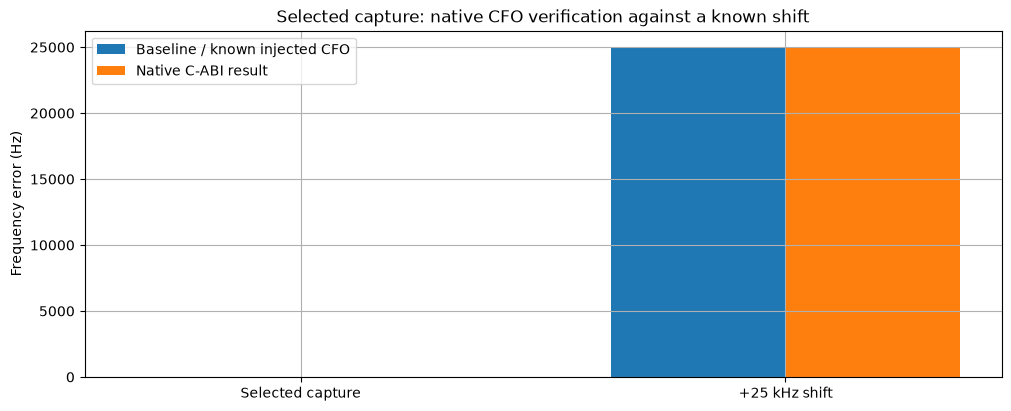

Verification report: reports\uwb_native_vsa_20261016.json


In [ ]:
# 9. Compare the selected native result with VSA measurements of the identical capture.
import hashlib
import json
import subprocess
from datetime import datetime, timezone

run_vsa_measurement = False
vsa_report = root / "reports/uwb_vsa_all_20261016.csv"
capture_relative = reference_capture.relative_to(root).as_posix()
capture_sha256 = hashlib.sha256(reference_capture.read_bytes()).hexdigest()
packet_config = 0 if mode == "802.15.4A" else int(settings["StsPacketConfig"])
vsa_command = [sys.executable, "-u", str(root / "tools/legacy_correlate.py"),
               "--only", f"802.15.4z_HrpUwb/{reference_capture.stem}"]
print("Optional VSA replay command:", subprocess.list2cmdline(vsa_command))
print("The saved report is used by default; live replay requires a running VSA and does not restart it.")
vsa_rows = []
if run_vsa_measurement:
    measurement_run = subprocess.run(vsa_command, cwd=root, capture_output=True, text=True, timeout=240)
    print(measurement_run.stdout)
    measurement_run.check_returncode()
    live_row = json.loads(next(line for line in reversed(measurement_run.stdout.splitlines()) if line.startswith("{")))
    live_row.update(capture=capture_relative, capture_sha256=capture_sha256,
                    measured_utc=datetime.now(timezone.utc).isoformat())
    vsa_rows = [live_row]
elif vsa_report.exists() and vsa_report.stat().st_size:
    with vsa_report.open(newline="", encoding="utf-8-sig") as stream:
        vsa_rows = [row for row in csv.DictReader(stream)
                    if row.get("family") == "802.15.4z_HrpUwb"
                    and row.get("waveform") == reference_capture.stem
                    and row.get("capture") == capture_relative]
correlation = None
vsa_tables = None
vsa_row = vsa_rows[-1] if vsa_rows else {}
vsa_status = "not_verified"
vsa_note = "No completed VSA measurement for the selected capture."
if vsa_row:
    if vsa_row.get("capture_sha256") != capture_sha256:
        vsa_status = "stale_capture"
        vsa_note = "The VSA row's SHA256 does not match the current capture; comparison rejected."
    elif vsa_row.get("status") == "ok" and vsa_row.get("vsa_all"):
        vsa_tables = json.loads(vsa_row["vsa_all"])
        correlation = check_uwb_correlation(reference_result.as_dict(), vsa_tables, packet_config=packet_config)
        vsa_status = "pass" if correlation["pass"] else "fail"
        vsa_note = "Native/VSA CFO compared; NRMSE values are VSA-only measurements of the same hashed capture."
        print(json.dumps(correlation, indent=2))
    else:
        vsa_status = "unsupported" if vsa_row.get("status") == "unsupported" else "not_verified"
        vsa_note = f"VSA attempt status {vsa_row.get('status')}: {vsa_row.get('note', '')}"
print(f"89600 correlation: {vsa_status.upper()} -- {vsa_note}")

figure, axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
positions = np.arange(2)
axis.bar(positions - 0.18, [reference_result.frequencyErrorHz, reference_result.frequencyErrorHz + injected_cfo_hz],
         width=0.36, label="Baseline / known injected CFO")
axis.bar(positions + 0.18, [reference_result.frequencyErrorHz, shifted_reference_result.frequencyErrorHz],
         width=0.36, label="Native C-ABI result")
axis.set(xticks=positions, xticklabels=["Selected capture", "+25 kHz shift"], ylabel="Frequency error (Hz)",
         title="Selected capture: native CFO verification against a known shift")
axis.legend()
plt.show()
if correlation is not None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    axes[0].bar(["Native", "89600"], [correlation["native_frequency_error_hz"], correlation["vsa_frequency_error_hz"]])
    axes[0].set(ylabel="Frequency error (Hz)", title="Selected recording: CFO comparison")
    quality_fields = [(label, field) for label, field in [("SHR", "ShrNrmse"), ("PHR", "PhrNrmse"),
                                                         ("PSDU", "PsduNrmse"), ("STS", "StsNrmse")]
                      if field in vsa_tables]
    axes[1].bar([entry[0] for entry in quality_fields], [vsa_tables[entry[1]] for entry in quality_fields])
    axes[1].set(ylabel="NRMSE (%)", title="89600-only quality metrics; no native equivalent")
    plt.show()

verification = {"timestamp_utc": datetime.now(timezone.utc).isoformat(),
                "capture": capture_relative, "capture_sha256": capture_sha256,
                "native_version": demod.version(), "native_metrics": reference_result.as_dict(),
                "native_config": {"phyMode": reference_config.phyMode, "syncLength": reference_config.syncLength,
                                  "sampleRate": reference_config.sampleRate, "chipRateHz": reference_config.chipRateHz},
                "legacy_hopping_convention": settings.get("LegacyHoppingConvention"),
                "native_checks": {"reference_sync": True, "injected_cfo_hz": injected_cfo_hz,
                                  "recovered_cfo_shift_hz": measured_cfo_shift_hz, "empty_input_rejected": True},
                "cmake_unit_tests": "not_run: this notebook does not execute the CMake test suite",
                "vsa_source_csv": None if run_vsa_measurement else vsa_report.relative_to(root).as_posix(),
                "vsa_measured_utc": vsa_row.get("measured_utc"),
                "vsa_status": vsa_status, "vsa_note": vsa_note, "vsa_tables": vsa_tables,
                "correlation": correlation,
                "limitations": "Native core exposes burst/preamble/CFO only; no native PHR/PSDU EVM or payload decoding."}
verification_path = root / "reports/uwb_native_vsa_20261016.json"
verification_path.parent.mkdir(parents=True, exist_ok=True)
verification_path.write_text(json.dumps(verification, indent=2) + "\n", encoding="utf-8")
print(f"Verification report: {verification_path.relative_to(root)}")

In [ ]:
# 10. Verify every distinct readable UWB capture, retaining failures and unsupported modes.
import re
import json
from datetime import datetime, timezone
from nrdemod.vsa import load_iq

batch_native_modes = {"BPRF": demod.UWB_BPRF, "HPRF": demod.UWB_HPRF,
                      "EHPRF": demod.UWB_EHPRF, "802.15.4a": demod.UWB_BPRF}
uwb_capture_paths = sorted([
    *(root / "captures/generated/uwb").glob("*.txt"),
    *(root / "captures/tdc_reference_plaintext/802.15.4z_HrpUwb").glob("*.txt"),
])
uwb_batch_rows = []
uwb_batch_native_path = root / "reports/uwb_all_20261016_native.json"
for waveform_path in uwb_capture_paths:
    generated = waveform_path.parent.name == "uwb"
    parameter_path = (waveform_path.with_suffix(".para2") if generated else
                      root / "captures/tdc_reference/802.15.4z_HrpUwb" / waveform_path.with_suffix(".para2").name)
    parameters = {}
    with parameter_path.open(newline="", encoding="utf-8-sig") as stream:
        for entry in csv.reader(stream, skipinitialspace=True):
            if len(entry) >= 4 and entry[0].strip() == "INPUT":
                parameters[entry[1].strip()] = entry[3].strip()
    if generated:
        waveform_mode = parameters["Mode"]
        sync_length = int(parameters["SyncLength"])
        packet_config = int(parameters["StsPacketConfig"])
    else:
        match = re.match(r"802154HrpUwb_(BPRF|HPRF)_SP(\d)_Code(\d+)_Sync(\d+)_Delta(\d+)_SFD(\d+)", waveform_path.stem)
        if match is None:
            raise ValueError(f"Unknown reference naming: {waveform_path.name}")
        waveform_mode = match.group(1)
        packet_config = int(match.group(2))
        sync_length = int(match.group(4))
    row = {"capture": waveform_path.relative_to(root).as_posix(),
           "source": "generated" if generated else "tdc_reference_plaintext",
           "mode": waveform_mode, "packet_config": packet_config,
           "sync_length": sync_length, "native_status": "not_run", "native_metrics": None,
           "injected_cfo_hz": 25000.0, "recovered_cfo_shift_hz": None,
           "cfo_test_pass": None, "vsa_status": "not_verified", "correlation_status": "not_verified", "note": ""}
    if waveform_mode not in batch_native_modes:
        row.update(native_status="unsupported", note=f"Unsupported PHY mode: {waveform_mode}")
    else:
        try:
            batch_iq, batch_fs = load_iq(str(waveform_path))
            if batch_fs is None or batch_fs <= 0:
                raise ValueError("Capture has no valid sample rate")
            batch_config = demod.Config(sampleRate=batch_fs, phyMode=batch_native_modes[waveform_mode],
                                        syncLength=sync_length)
            batch_result = demod.demodulate(demod.UWB_HRP, batch_iq, batch_config)
            row.update(sample_rate_hz=batch_fs, num_samples=batch_iq.size, native_phy_mode=batch_config.phyMode,
                       native_metrics=batch_result.as_dict())
            if batch_result.ok and batch_result.burstFound and batch_result.syncFound:
                batch_shifted = batch_iq * np.exp(2j * np.pi * row["injected_cfo_hz"] * np.arange(batch_iq.size) / batch_fs)
                batch_shift_result = demod.demodulate(demod.UWB_HRP, batch_shifted, batch_config)
                recovered = float(batch_shift_result.frequencyErrorHz - batch_result.frequencyErrorHz)
                cfo_pass = bool(batch_shift_result.ok and batch_shift_result.syncFound and np.isfinite(recovered)
                                and abs(recovered - row["injected_cfo_hz"]) <= 100)
                row.update(native_status="pass" if cfo_pass else "fail", recovered_cfo_shift_hz=recovered,
                           cfo_test_pass=cfo_pass)
                del batch_shifted
            else:
                row.update(native_status="fail", note=batch_result.error or "Native burst/preamble synchronization failed")
            del batch_iq
        except Exception as error:
            row.update(native_status="error", note=f"{type(error).__name__}: {error}")
    uwb_batch_rows.append(row)
    uwb_batch_native_path.write_text(json.dumps({"timestamp_utc": datetime.now(timezone.utc).isoformat(),
                                                 "native_version": demod.version(), "rows": uwb_batch_rows}, indent=2) + "\n",
                                      encoding="utf-8")
    print(f"{waveform_path.name}: native={row['native_status']}, CFO check={row['cfo_test_pass']}")

print(f"Distinct plaintext captures: {len(uwb_batch_rows)}")
print({status: sum(row["native_status"] == status for row in uwb_batch_rows)
       for status in ("pass", "fail", "error", "unsupported")})
print("Native checks cover repetition synchronization and CFO only, not code-index verification or payload decoding.")

UWB_4a_ch9_CI3_PRF15M6_6M81_PSDU100.txt: native=pass, CFO check=True


UWB_4ab_EHPRF_ch5_7M8_LDPC_PSDU127.txt: native=pass, CFO check=True


UWB_4ab_EHPRF_ch9_124M8_LDPC_PSDU1024.txt: native=pass, CFO check=True


UWB_4ab_EHPRF_ch9_62M4_BCC_PSDU256.txt: native=pass, CFO check=True


UWB_4z_BPRF_ch5_CI10_SP1_PSDU127.txt: native=pass, CFO check=True


...

802154HrpUwb_BPRF_SP1_Code9_Sync64_Delta4_SFD2_PDR-L_FrameLeng127_STS-SegLen64-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True


802154HrpUwb_BPRF_SP3_Code9_Sync64_Delta4_SFD2_STS-SegLen64-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True


802154HrpUwb_HPRF_SP0_Code25_Sync64_Delta4_SFD2_PDR-L_FrameLeng1023_RRCMinPhase_OSR4.txt: native=pass, CFO check=True


802154HrpUwb_HPRF_SP1_Code25_Sync64_Delta4_SFD2_PDR-L_FrameLeng1023_STS-SegLen64-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True


802154HrpUwb_HPRF_SP3_Code25_Sync64_Delta4_SFD3_STS-SegLen128-SegNum1_RRCMinPhase_OSR4.txt: native=pass, CFO check=True
Distinct plaintext captures: 15
{'pass': 15, 'fail': 0, 'error': 0, 'unsupported': 0}
Native checks cover repetition synchronization and CFO only, not code-index verification or payload decoding.


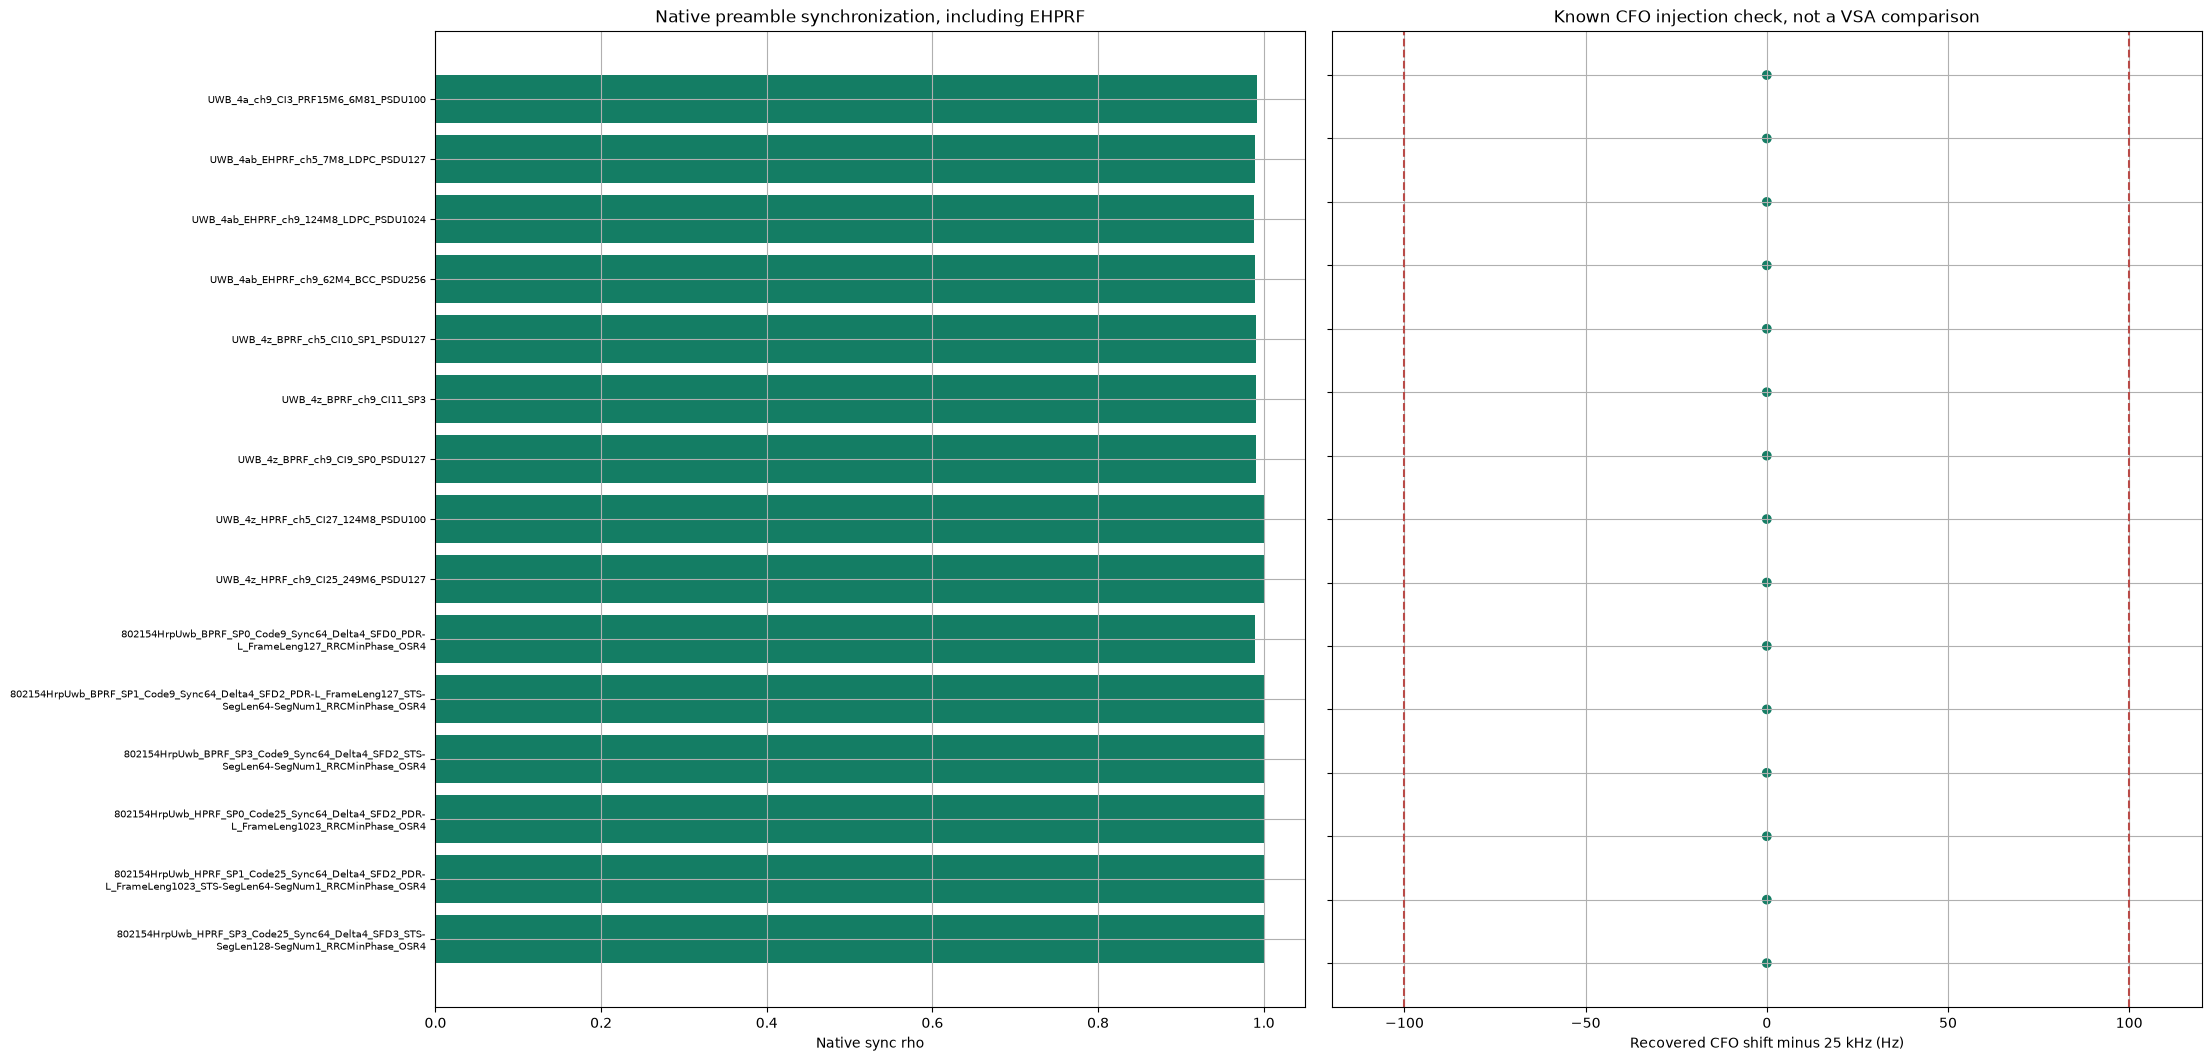

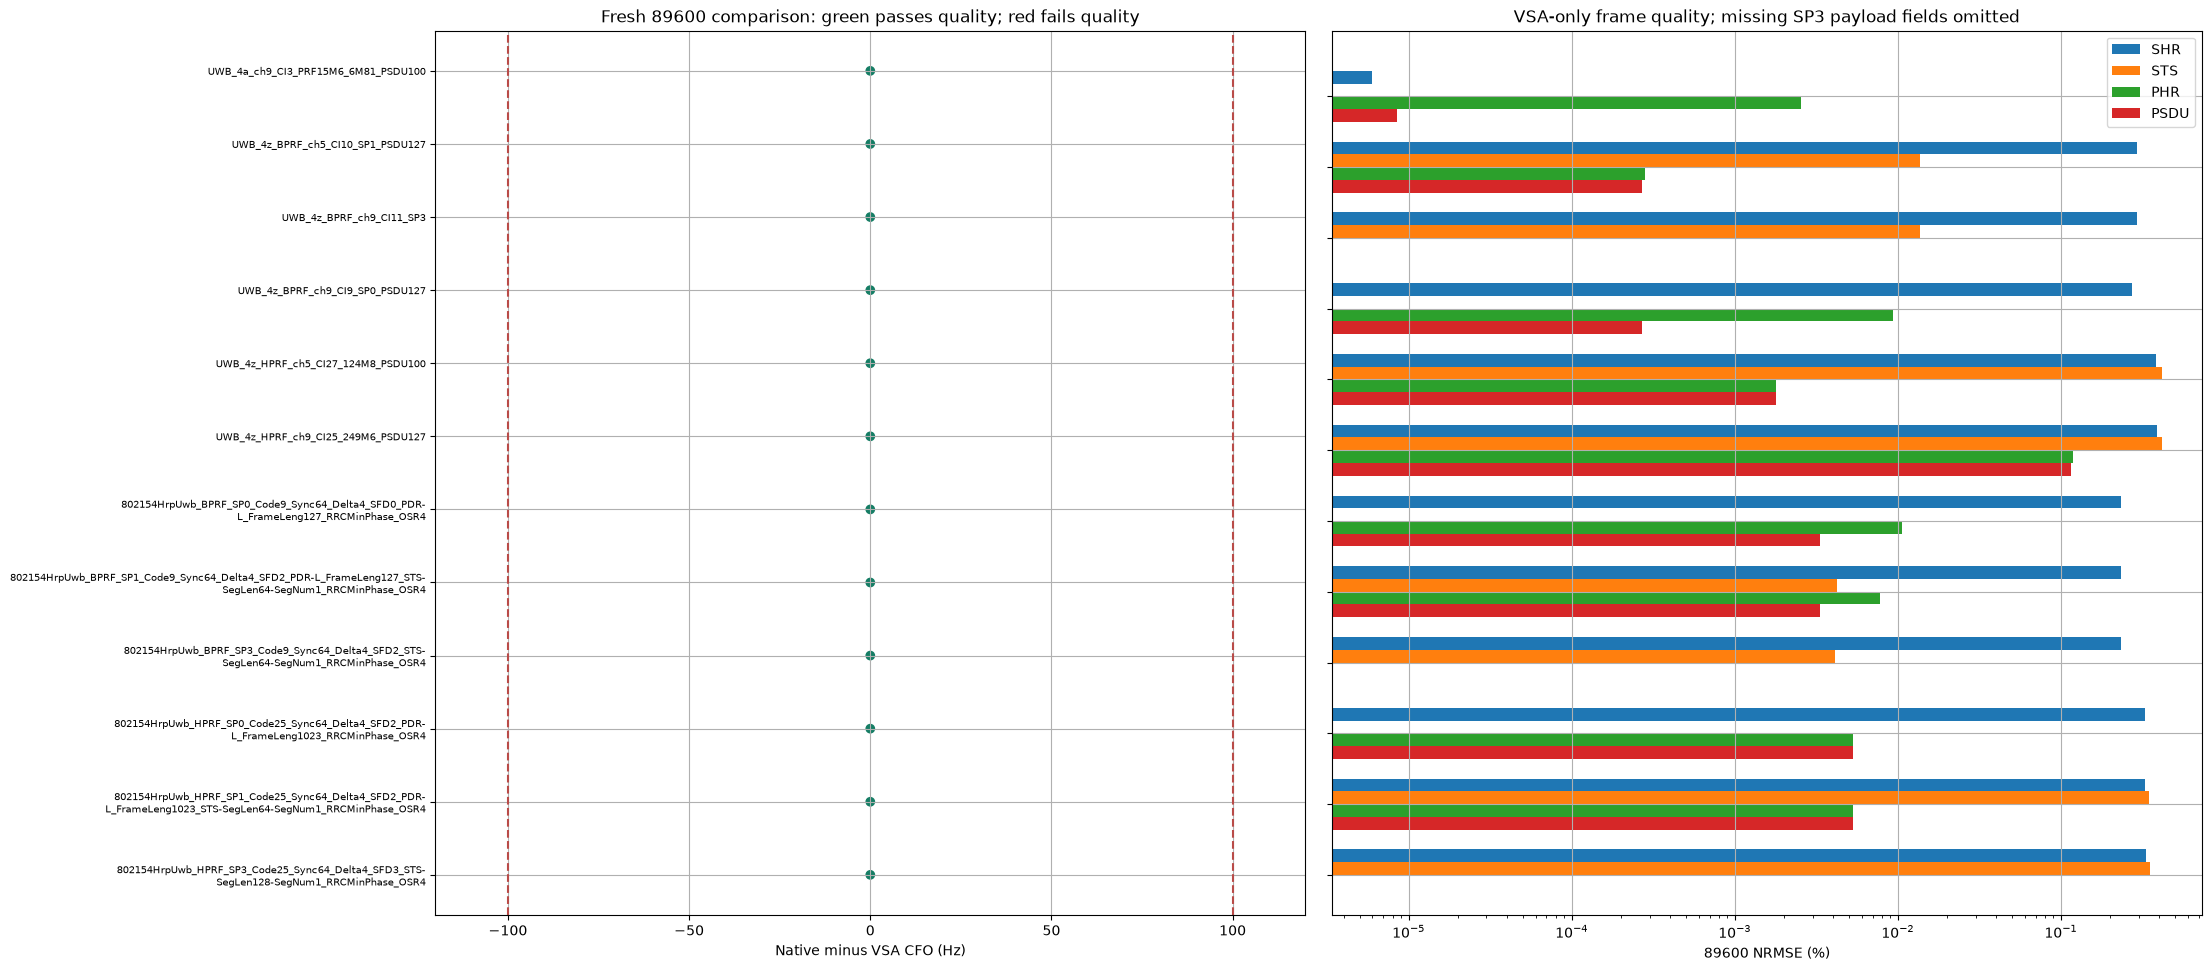

Summary: {'captures': 15, 'native_pass': 15, 'correlation_pass': 12, 'correlation_fail': 0, 'vsa_unsupported': 3, 'vsa_invalid_results': 0}
VSA raw rows: 15 | valid CFO comparisons: 12
Limits: CFO difference <= 100 Hz; SHR/STS <= 0.5%; PHR/PSDU <= 2%.
EHPRF remains native-only because this VSA release has no EHPRF PHY mode.
Reports: reports\uwb_all_20261016.json reports\uwb_all_20261016.csv


In [ ]:
# 11. Correlate identical hashed captures against saved fresh 89600 measurements.
import textwrap

connection_path = root / "reports/uwb_all_20261016_vsa_connection.json"
connection_attempt = (json.loads(connection_path.read_text(encoding="utf-8")) if connection_path.exists()
                      else {"status": "not_attempted"})
measurement_path = root / "reports/uwb_vsa_all_20261016.csv"
measurement_rows = {}
if measurement_path.exists():
    with measurement_path.open(newline="", encoding="utf-8-sig") as stream:
        measurement_rows = {row["capture"]: row for row in csv.DictReader(stream)}
batch_report_rows = []
for native_row in uwb_batch_rows:
    report_row = dict(native_row)
    measured = measurement_rows.get(report_row["capture"])
    report_row.update(vsa_status="not_run", correlation_status="not_verified", correlation=None,
                      vsa_measured_utc=None, vsa_tables=None,
                      vsa_note="No saved VSA measurement for this capture; connection alone is not a correlation.")
    if measured:
        report_row.update(vsa_status=measured["status"], vsa_measured_utc=measured["measured_utc"],
                          vsa_note=measured.get("note", ""))
        if measured["status"] == "ok" and measured.get("vsa_all"):
            with (root / report_row["capture"]).open("rb") as stream:
                capture_digest = hashlib.file_digest(stream, "sha256").hexdigest()
            report_row["capture_sha256"] = capture_digest
            if capture_digest != measured.get("capture_sha256"):
                report_row.update(vsa_status="input_mismatch", vsa_note="Capture changed since the saved VSA measurement.")
            else:
                tables = json.loads(measured["vsa_all"])
                report_row["vsa_tables"] = tables
                packet_config = 0 if report_row["mode"] == "802.15.4a" else report_row["packet_config"]
                try:
                    checked = check_uwb_correlation(report_row["native_metrics"], tables, packet_config=packet_config)
                    report_row.update(vsa_status="measured", correlation_status="pass" if checked["pass"] else "fail",
                                      correlation=checked, vsa_note="CFO compared on identical IQ; NRMSE is VSA-only, not native payload EVM.")
                    if not checked["vsa_lock_quality_pass"]:
                        failed_quality = [name for name, limit in checked["limits_percent"].items()
                                          if name in tables and not 0 <= float(tables[name]) <= limit]
                        report_row["vsa_note"] = "VSA quality checks failed: " + ", ".join(failed_quality) + "; waveform/setup compatibility needs investigation."
                except (ValueError, TypeError) as error:
                    report_row.update(vsa_status="invalid_results", correlation_status="fail", vsa_note=str(error))
    batch_report_rows.append(report_row)

batch_summary = {"captures": len(batch_report_rows),
                 "native_pass": sum(row["native_status"] == "pass" for row in batch_report_rows),
                 "correlation_pass": sum(row["correlation_status"] == "pass" for row in batch_report_rows),
                 "correlation_fail": sum(row["correlation_status"] == "fail" for row in batch_report_rows),
                 "vsa_unsupported": sum(row["vsa_status"] == "unsupported" for row in batch_report_rows),
                 "vsa_invalid_results": sum(row["vsa_status"] == "invalid_results" for row in batch_report_rows)}
batch_report = {"timestamp_utc": datetime.now(timezone.utc).isoformat(), "summary": batch_summary,
                "native_version": demod.version(), "vsa_connection_attempt": connection_attempt,
                "vsa_source_csv": str(measurement_path.relative_to(root)),
                "limits": {"cfo_difference_hz": 100.0, "shr_sts_nrmse_percent": 0.5, "phr_psdu_nrmse_percent": 2.0},
                "limitations": "Native measures burst/preamble/CFO only, not payload EVM or decoding. VSA NRMSE table values are percentages. VSA 2026_U2 has no EHPRF PHY mode. Binary TDC .wfm files share the listed plaintext waveforms.",
                "rows": batch_report_rows}
batch_report_path = root / "reports/uwb_all_20261016.json"
batch_report_path.write_text(json.dumps(batch_report, indent=2) + "\n", encoding="utf-8")
batch_csv_path = root / "reports/uwb_all_20261016.csv"
fields = ["capture", "source", "mode", "packet_config", "native_phy_mode", "sync_length", "sample_rate_hz", "num_samples",
          "native_status", "native_sync_rho", "native_cfo_hz", "injected_cfo_hz", "recovered_cfo_shift_hz", "cfo_test_pass",
          "vsa_status", "correlation_status", "vsa_measured_utc", "vsa_cfo_hz", "cfo_difference_hz", "cfo_agreement_pass",
          "vsa_lock_quality_pass", "vsa_shr_nrmse_percent", "vsa_sts_nrmse_percent", "vsa_phr_nrmse_percent",
          "vsa_psdu_nrmse_percent", "capture_sha256", "note", "vsa_note"]
with batch_csv_path.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=fields, extrasaction="ignore")
    writer.writeheader()
    for report_row in batch_report_rows:
        metrics = report_row["native_metrics"] or {}
        checked = report_row["correlation"] or {}
        writer.writerow({**report_row, **checked, "native_sync_rho": metrics.get("syncRho"),
                         "native_cfo_hz": metrics.get("frequencyErrorHz"), "vsa_cfo_hz": checked.get("vsa_frequency_error_hz")})

plot_rows = [row for row in batch_report_rows if row["native_metrics"] is not None]
if plot_rows:
    figure, axes = plt.subplots(1, 2, figsize=(22, max(7, len(plot_rows) * 0.7)), constrained_layout=True)
    positions = np.arange(len(plot_rows))
    labels = [textwrap.fill(Path(row["capture"]).stem, width=70) for row in plot_rows]
    colors = ["#147d64" if row["native_status"] == "pass" else "#b94b48" for row in plot_rows]
    axes[0].barh(positions, [row["native_metrics"]["syncRho"] for row in plot_rows], color=colors)
    axes[0].set(yticks=positions, yticklabels=labels, xlim=(0, 1.05), xlabel="Native sync rho",
                title="Native preamble synchronization, including EHPRF")
    axes[0].tick_params(axis="y", labelsize=7)
    axes[0].invert_yaxis()
    errors = [row["recovered_cfo_shift_hz"] - row["injected_cfo_hz"]
              if row["recovered_cfo_shift_hz"] is not None else np.nan for row in plot_rows]
    axes[1].scatter(errors, positions, c=colors)
    axes[1].axvline(-100, color="#b94b48", linestyle="--")
    axes[1].axvline(100, color="#b94b48", linestyle="--")
    axes[1].set(yticks=positions, yticklabels=[], xlim=(-120, 120), xlabel="Recovered CFO shift minus 25 kHz (Hz)",
                title="Known CFO injection check, not a VSA comparison")
    axes[1].invert_yaxis()
    plt.show()

compared_rows = [row for row in batch_report_rows if row["correlation"] is not None]
if compared_rows:
    figure, axes = plt.subplots(1, 2, figsize=(22, max(7, len(compared_rows) * 0.8)), constrained_layout=True)
    positions = np.arange(len(compared_rows))
    labels = [textwrap.fill(Path(row["capture"]).stem, width=70) for row in compared_rows]
    colors = ["#147d64" if row["correlation_status"] == "pass" else "#b94b48" for row in compared_rows]
    axes[0].scatter([row["correlation"]["cfo_difference_hz"] for row in compared_rows], positions, c=colors)
    axes[0].axvline(-100, color="#b94b48", linestyle="--")
    axes[0].axvline(100, color="#b94b48", linestyle="--")
    axes[0].set(yticks=positions, yticklabels=labels, xlim=(-120, 120), xlabel="Native minus VSA CFO (Hz)",
                title="Fresh 89600 comparison: green passes quality; red fails quality")
    axes[0].tick_params(axis="y", labelsize=7)
    axes[0].invert_yaxis()
    for offset, label in enumerate(("shr", "sts", "phr", "psdu")):
        values = [row["correlation"].get(f"vsa_{label}_nrmse_percent") for row in compared_rows]
        axes[1].barh(positions + (offset - 1.5) * 0.18, [value if value is not None else np.nan for value in values],
                     height=0.18, label=label.upper())
    axes[1].set(yticks=positions, yticklabels=[], xscale="log", xlabel="89600 NRMSE (%)",
                title="VSA-only frame quality; missing SP3 payload fields omitted")
    axes[1].invert_yaxis()
    axes[1].legend()
    plt.show()

print("Summary:", batch_summary)
print("VSA raw rows:", len(measurement_rows), "| valid CFO comparisons:", len(compared_rows))
print("Limits: CFO difference <= 100 Hz; SHR/STS <= 0.5%; PHR/PSDU <= 2%.")
print("EHPRF remains native-only because this VSA release has no EHPRF PHY mode.")
print("Reports:", batch_report_path.relative_to(root), batch_csv_path.relative_to(root))